In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk('/kaggle/input'):
  for filename in filenames:
    print(os.path.join(dirname, filename))
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns


In [3]:
folder_path = '/kaggle/input/competitions/ieee-fraud-detection/'
train_identity = pd.read_csv(f'{folder_path}train_identity.csv')
train_transaction = pd.read_csv(f'{folder_path}train_transaction.csv')
test_identity = pd.read_csv(f'{folder_path}test_identity.csv')
test_transaction = pd.read_csv(f'{folder_path}test_transaction.csv')
sub = pd.read_csv(f'{folder_path}sample_submission.csv')

In [4]:
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
train_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [6]:
print("Transaction columns:")
print(train_transaction.columns.tolist())

print("\nIdentity columns:")
print(train_identity.columns.tolist())

Transaction columns:
['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V

In [7]:
print("TRANSACTION DATA")
train_transaction.info()

print("\nIDENTITY DATA")
train_identity.info()

TRANSACTION DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 1.7+ GB

IDENTITY DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 41 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionID  144233 non-null  int64  
 1   id_01          144233 non-null  float64
 2   id_02          140872 non-null  float64
 3   id_03          66324 non-null   float64
 4   id_04          66324 non-null   float64
 5   id_05          136865 non-null  float64
 6   id_06          136865 non-null  float64
 7   id_07          5155 non-null    float64
 8   id_08          5155 non-null    float64
 9   id_09          74926 non-null   float64
 10  id_10          74926 non-null   float64
 11  id_11          140978 non-null  float64
 12  id_12          144233 non-null  obj

In [8]:
transaction_memory = (
    train_transaction.memory_usage(deep=True).sum()
    / 1024**2
)

identity_memory = (
    train_identity.memory_usage(deep=True).sum()
    / 1024**2
)

print(f"Transaction memory: {transaction_memory:.2f} MB")
print(f"Identity memory: {identity_memory:.2f} MB")

Transaction memory: 2062.07 MB
Identity memory: 143.14 MB


In [9]:
# Check target distribution

print(train_transaction['isFraud'].value_counts())

print("\nPercentage distribution:")

print(
    train_transaction['isFraud']
    .value_counts(normalize=True) * 100
)

isFraud
0    569877
1     20663
Name: count, dtype: int64

Percentage distribution:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


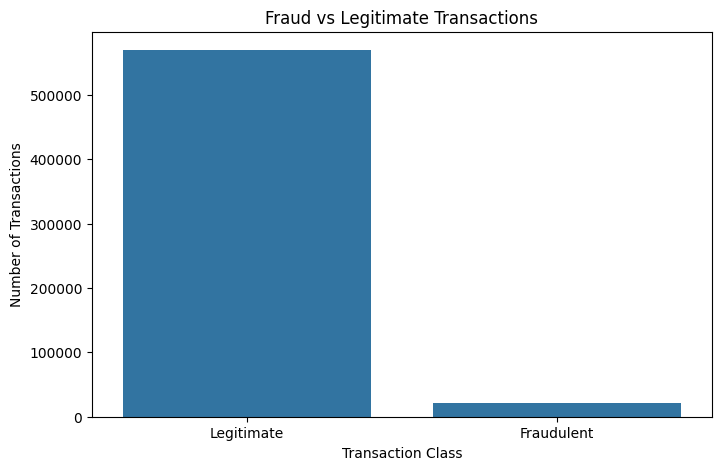

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_transaction,
    x='isFraud'
)

plt.title('Fraud vs Legitimate Transactions')
plt.xlabel('Transaction Class')
plt.ylabel('Number of Transactions')

plt.xticks([0, 1], ['Legitimate', 'Fraudulent'])

plt.show()

### Target Variable Analysis

The target variable is `isFraud`.

- 0 represents legitimate transactions.
- 1 represents fraudulent transactions.

The dataset contains an imbalanced class distribution,
with legitimate transactions significantly outnumbering
fraudulent transactions.

This imbalance will influence model evaluation and
the selection of appropriate performance metrics.

In [11]:
print(
    "Transaction duplicate rows:",
    train_transaction.duplicated().sum()
)

print(
    "Identity duplicate rows:",
    train_identity.duplicated().sum()
)

print(
    "Duplicate transaction IDs:",
    train_transaction['TransactionID'].duplicated().sum()
)

print(
    "Duplicate identity IDs:",
    train_identity['TransactionID'].duplicated().sum()
)

Transaction duplicate rows: 0
Identity duplicate rows: 0
Duplicate transaction IDs: 0
Duplicate identity IDs: 0


For easier investigation later, we will create a reusable function that looks for:
1. **null** values
2. its percentage
3. unique values
4. data type

In [12]:
def missing_report(df):

    report = pd.DataFrame({
        'Missing_Count': df.isnull().sum(),
        'Missing_Percentage': df.isnull().mean() * 100,
        'Unique_Values': df.nunique(),
        'Data_Type': df.dtypes.astype(str)
    })

    return report.sort_values(
        by='Missing_Percentage',
        ascending=False
    )

In [13]:
transaction_missing = missing_report(train_transaction)
identity_missing = missing_report(train_identity)

display(transaction_missing.head(20))
display(identity_missing.head(20))

,Missing_Count,Missing_Percentage,Unique_Values,Data_Type
dist2,552913,93.628374,1751,float64
D7,551623,93.409930,597,float64
D13,528588,89.509263,577,float64
D14,528353,89.469469,802,float64
D12,525823,89.041047,635,float64
D6,517353,87.606767,829,float64
D9,515614,87.312290,24,float64
D8,515614,87.312290,12353,float64
V153,508595,86.123717,19,float64
V149,508595,86.123717,21,float64


,Missing_Count,Missing_Percentage,Unique_Values,Data_Type
id_24,139486,96.708798,12,float64
id_25,139101,96.441868,341,float64
id_07,139078,96.425922,84,float64
id_08,139078,96.425922,94,float64
id_21,139074,96.423149,490,float64
id_26,139070,96.420375,95,float64
id_23,139064,96.416215,3,object
id_27,139064,96.416215,2,object
id_22,139064,96.416215,25,float64
id_18,99120,68.722137,18,float64


Here we will look for a constant feature that contains only one unique non-value

In [14]:
def constant_columns(df):

    return [
        col for col in df.columns
        if df[col].nunique(dropna=True) <= 1
    ]


transaction_constant = constant_columns(train_transaction)
identity_constant = constant_columns(train_identity)

print("Constant transaction columns:", transaction_constant)
print("Constant identity columns:", identity_constant)

Constant transaction columns: []
Constant identity columns: []


We will merge the datasets to work with the whole dataframe

In [15]:
train = pd.merge(train_transaction, train_identity, on='TransactionID', how='left')
test = pd.merge(test_transaction, test_identity, on='TransactionID', how='left')

In [16]:

# Check TransactionID uniqueness
print("Transaction IDs in transaction data:")
print("Unique:", train_transaction['TransactionID'].is_unique)

print("\nTransaction IDs in identity data:")
print("Unique:", train_identity['TransactionID'].is_unique)

# Merge transaction and identity data


print("\nMerged training dataset shape:", train.shape)

# Verify that no transaction rows were lost
print("Original transaction rows:", len(train_transaction))
print("Merged training rows:", len(train))

# Check identity information coverage
identity_available = train['id_01'].notna().sum()

print(
    f"Transactions with identity information: "
    f"{identity_available:,} "
    f"({identity_available / len(train) * 100:.2f}%)"
)


Transaction IDs in transaction data:
Unique: True

Transaction IDs in identity data:
Unique: True

Merged training dataset shape: (590540, 434)
Original transaction rows: 590540
Merged training rows: 590540
Transactions with identity information: 144,233 (24.42%)


In [17]:

# Identify transactions that have a matching identity record
train['has_identity'] = train['TransactionID'].isin(
    train_identity['TransactionID']
).astype('int8')

# Count transactions with and without identity records
print(train['has_identity'].value_counts())

print("\nIdentity availability percentage:")
print(train['has_identity'].value_counts(normalize=True) * 100)

# Verify the relationship
print(
    "\nTransactions with identity records:",
    train['has_identity'].sum()
)


has_identity
0    446307
1    144233
Name: count, dtype: int64

Identity availability percentage:
has_identity
0    75.576083
1    24.423917
Name: proportion, dtype: float64

Transactions with identity records: 144233


In [18]:
missing_report(train).head(20)


,Missing_Count,Missing_Percentage,Unique_Values,Data_Type
id_24,585793,99.196159,12,float64
id_25,585408,99.130965,341,float64
id_07,585385,99.127070,84,float64
id_08,585385,99.127070,94,float64
id_21,585381,99.126393,490,float64
id_26,585377,99.125715,95,float64
id_27,585371,99.124699,2,object
id_23,585371,99.124699,3,object
id_22,585371,99.124699,25,float64
dist2,552913,93.628374,1751,float64


In [19]:

# Get identity feature names, excluding the shared key
identity_columns = [
    col for col in train_identity.columns
    if col != 'TransactionID'
]

# Analyze identity features only where identity records exist
identity_subset = train.loc[
    train['has_identity'] == 1,
    identity_columns
]

identity_conditional_missing = pd.DataFrame({
    'Missing_Count': identity_subset.isnull().sum(),
    'Missing_Percentage': identity_subset.isnull().mean() * 100,
    'Unique_Values': identity_subset.nunique(),
    'Data_Type': identity_subset.dtypes.astype(str)
}).sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(identity_conditional_missing.head(25))


,Missing_Count,Missing_Percentage,Unique_Values,Data_Type
id_24,139486,96.708798,12,float64
id_25,139101,96.441868,341,float64
id_07,139078,96.425922,84,float64
id_08,139078,96.425922,94,float64
id_21,139074,96.423149,490,float64
id_26,139070,96.420375,95,float64
id_27,139064,96.416215,2,object
id_22,139064,96.416215,25,float64
id_23,139064,96.416215,3,object
id_18,99120,68.722137,18,float64


In [20]:

# Identify columns with no available values
all_missing_cols = [
    col for col in train.columns
    if train[col].isna().all()
]

# Identify columns with only one non-missing unique value
constant_cols = [
    col for col in train.columns
    if train[col].nunique(dropna=True) <= 1
]

print("Completely empty columns:", len(all_missing_cols))
print(all_missing_cols)

print("\nConstant columns:", len(constant_cols))
print(constant_cols)

# Remove completely empty and constant columns
# Keep TransactionID and isFraud
cols_to_drop = [
    col for col in set(all_missing_cols + constant_cols)
    if col not in ['TransactionID', 'isFraud']
]

train.drop(columns=cols_to_drop, inplace=True)

print("\nShape after removing unnecessary columns:", train.shape)


Completely empty columns: 0
[]

Constant columns: 0
[]

Shape after removing unnecessary columns: (590540, 435)


In [21]:

# Convert relative transaction time into useful features

train['TransactionDay'] = (
    train['TransactionDT'] // 86400
).astype('int32')

train['TransactionHour'] = (
    (train['TransactionDT'] // 3600) % 24
).astype('int8')

print(
    train[
        ['TransactionDT', 'TransactionDay', 'TransactionHour']
    ].head()
)


   TransactionDT  TransactionDay  TransactionHour
0          86400               1                0
1          86401               1                0
2          86469               1                0
3          86499               1                0
4          86506               1                0


In [22]:

# Inspect transaction amounts first
print(train['TransactionAmt'].describe())
print("Minimum amount:", train['TransactionAmt'].min())

# Create a log-transformed amount feature
if (train['TransactionAmt'] < 0).any():
    raise ValueError("Negative transaction amounts found; inspect before log transformation.")

train['TransactionAmt_log'] = np.log1p(
    train['TransactionAmt']
)

print(
    train[
        ['TransactionAmt', 'TransactionAmt_log']
    ].head()
)


count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64
Minimum amount: 0.251
   TransactionAmt  TransactionAmt_log
0            68.5            4.241327
1            29.0            3.401197
2            59.0            4.094345
3            50.0            3.931826
4            50.0            3.931826


In [23]:

# Extract email domains
for col in ['P_emaildomain', 'R_emaildomain']:
    if col in train.columns:
        new_col = col + '_domain'

        train[new_col] = (
            train[col]
            .astype('string')
            .str.lower()
            .str.strip()
        )

        print(f"Created: {new_col}")

# Inspect results
email_features = [
    col for col in train.columns
    if col.endswith('_domain')
]

display(train[email_features].head())


Created: P_emaildomain_domain
Created: R_emaildomain_domain


,P_emaildomain_domain,R_emaildomain_domain
0,<NA>,<NA>
1,gmail.com,<NA>
2,outlook.com,<NA>
3,yahoo.com,<NA>
4,gmail.com,<NA>


In [24]:

# Select partially missing features with at least 50% missing values
missing_rates = train.isna().mean()

missing_indicator_cols = [
    col for col in train.columns
    if 0.50 <= missing_rates[col] < 1.0
    and col not in ['isFraud', 'TransactionID']
]

# Create missingness indicators
for col in missing_indicator_cols:
    train[col + '_missing'] = (
        train[col].isna().astype('int8')
    )

print("Missingness indicators created:", len(missing_indicator_cols))
print("New dataset shape:", train.shape)


/tmp/ipykernel_50/2493641848.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[col + '_missing'] = (
/tmp/ipykernel_50/2493641848.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[col + '_missing'] = (
/tmp/ipykernel_50/2493641848.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
 

Missingness indicators created: 215
New dataset shape: (590540, 655)


/tmp/ipykernel_50/2493641848.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[col + '_missing'] = (
/tmp/ipykernel_50/2493641848.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[col + '_missing'] = (
/tmp/ipykernel_50/2493641848.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
 

In [25]:

print("Final training dataset shape:", train.shape)

print("\nTarget distribution:")
print(train['isFraud'].value_counts(normalize=True) * 100)

print("\nMissing values in target:", train['isFraud'].isna().sum())

print("\nInfinite values:")
print(np.isinf(
    train.select_dtypes(include=np.number)
).sum().sum())

print("\nNew engineered features:")
print([
    col for col in train.columns
    if col in [
        'TransactionDay',
        'TransactionHour',
        'TransactionAmt_log',
        'P_emaildomain_domain',
        'R_emaildomain_domain'
    ]
])


Final training dataset shape: (590540, 655)

Target distribution:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Missing values in target: 0

Infinite values:
0

New engineered features:
['TransactionDay', 'TransactionHour', 'TransactionAmt_log', 'P_emaildomain_domain', 'R_emaildomain_domain']


In [26]:

# Sort transactions chronologically
train_sorted = train.sort_values(
    'TransactionDT'
).reset_index(drop=True)

# Use the earliest 80% for training
split_index = int(len(train_sorted) * 0.80)

train_part = train_sorted.iloc[:split_index].copy()
valid_part = train_sorted.iloc[split_index:].copy()

# Separate target and features
# TransactionID is retained in the data but excluded from model features
drop_from_features = ['isFraud', 'TransactionID']

X_train = train_part.drop(columns=drop_from_features)
y_train = train_part['isFraud']

X_valid = valid_part.drop(columns=drop_from_features)
y_valid = valid_part['isFraud']

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_valid.value_counts(normalize=True) * 100)

print("\nTraining time range:")
print(train_part['TransactionDT'].min(), "to",
      train_part['TransactionDT'].max())

print("\nValidation time range:")
print(valid_part['TransactionDT'].min(), "to",
      valid_part['TransactionDT'].max())


Training features: (472432, 653)
Validation features: (118108, 653)

Training target distribution:
isFraud
0    96.486478
1     3.513522
Name: proportion, dtype: float64

Validation target distribution:
isFraud
0    96.559082
1     3.440918
Name: proportion, dtype: float64

Training time range:
86400 to 12192842

Validation time range:
12192900 to 15811131


In [27]:

# Identify categorical columns
categorical_cols = X_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical columns:", len(numerical_cols))

# Inspect missingness in each group
print(
    "\nCategorical columns with most missing values:"
)
display(
    X_train[categorical_cols]
    .isna()
    .mean()
    .sort_values(ascending=False)
    .head(20)
)


Categorical columns: 33
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo', 'P_emaildomain_domain', 'R_emaildomain_domain']

Numerical columns: 620

Categorical columns with most missing values:


id_27                   0.990955
id_23                   0.990955
id_33                   0.869160
id_30                   0.860109
id_34                   0.859950
DeviceInfo              0.789311
id_16                   0.771040
R_emaildomain_domain    0.759500
R_emaildomain           0.759500
id_31                   0.751365
DeviceType              0.750995
id_36                   0.750660
id_15                   0.750660
id_35                   0.750660
id_28                   0.750660
id_29                   0.750660
id_38                   0.750660
id_37                   0.750660
id_12                   0.745013
M7                      0.634970
dtype: float64

In [28]:

# Numeric columns that represent categorical identifiers
numeric_categorical_candidates = [
    'card1',
    'card2',
    'card3',
    'card5',
    'addr1',
    'addr2'
]

# Keep only columns that actually exist
numeric_categorical_candidates = [
    col for col in numeric_categorical_candidates
    if col in X_train.columns
]

print("Numeric categorical candidates:")
print(numeric_categorical_candidates)

print("\nNumber of unique values:")
display(
    X_train[numeric_categorical_candidates]
    .nunique(dropna=True)
    .sort_values(ascending=False)
)


Numeric categorical candidates:
['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2']

Number of unique values:


card1    12730
card2      500
addr1      328
card5      113
card3      106
addr2       70
dtype: int64

In [29]:

categorical_analysis = pd.DataFrame({
    'Unique_Values': X_train[categorical_cols].nunique(dropna=True),
    'Missing_Percentage': X_train[categorical_cols].isna().mean() * 100
}).sort_values(
    by='Unique_Values',
    ascending=False
)

display(categorical_analysis)


,Unique_Values,Missing_Percentage
DeviceInfo,1639,78.931148
id_33,212,86.916001
id_31,110,75.136528
id_30,72,86.010897
R_emaildomain,60,75.949978
R_emaildomain_domain,60,75.949978
P_emaildomain_domain,59,15.575998
P_emaildomain,59,15.575998
ProductCD,5,0.000000
card6,4,0.175263


In [30]:

for original, engineered in [
    ('P_emaildomain', 'P_emaildomain_domain'),
    ('R_emaildomain', 'R_emaildomain_domain')
]:
    if original in X_train.columns and engineered in X_train.columns:
        original_normalized = (
            X_train[original].astype('string').str.lower().str.strip()
        )
        
        engineered_values = X_train[engineered].astype('string')

        same = (
            original_normalized.fillna('__MISSING__')
            == engineered_values.fillna('__MISSING__')
        ).all()

        print(f"{original} vs {engineered}: identical = {same}")

        if same:
            X_train.drop(columns=[original], inplace=True)
            X_valid.drop(columns=[original], inplace=True)
            print(f"Removed redundant feature: {original}")


P_emaildomain vs P_emaildomain_domain: identical = True
Removed redundant feature: P_emaildomain
R_emaildomain vs R_emaildomain_domain: identical = True
Removed redundant feature: R_emaildomain


In [31]:

# Add numeric identifiers to categorical features
numeric_categorical_candidates = [
    'card1', 'card2', 'card3',
    'card5', 'addr1', 'addr2'
]

categorical_cols = list(dict.fromkeys(
    categorical_cols + numeric_categorical_candidates
))

# Keep only existing columns
categorical_cols = [
    col for col in categorical_cols
    if col in X_train.columns
]

# Convert categorical columns to strings
# Use the same missing-value marker in train and validation
for col in categorical_cols:
    X_train[col] = (
        X_train[col]
        .astype('string')
        .fillna('__MISSING__')
        .astype(str)
    )

    X_valid[col] = (
        X_valid[col]
        .astype('string')
        .fillna('__MISSING__')
        .astype(str)
    )

print("Categorical features:", len(categorical_cols))
print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("\nRemaining categorical missing values:")
print(X_train[categorical_cols].isna().sum().sum())
print(X_valid[categorical_cols].isna().sum().sum())


Categorical features: 37
Training shape: (472432, 651)
Validation shape: (118108, 651)

Remaining categorical missing values:
0
0


In [32]:

print("Training data:")
print("Rows:", len(X_train))
print("Columns:", X_train.shape[1])
print("Categorical columns:", len(categorical_cols))

print("\nValidation data:")
print("Rows:", len(X_valid))
print("Columns:", X_valid.shape[1])

print("\nTarget distribution:")
print(y_train.value_counts())

print("\nNumeric infinite values:")
print(
    np.isinf(X_train.select_dtypes(include=np.number))
    .sum().sum()
)

print("\nCategorical data types:")
print(X_train[categorical_cols].dtypes.value_counts())


Training data:
Rows: 472432
Columns: 651
Categorical columns: 37

Validation data:
Rows: 118108
Columns: 651

Target distribution:
isFraud
0    455833
1     16599
Name: count, dtype: int64

Numeric infinite values:
0

Categorical data types:
object    37
Name: count, dtype: int64


In [33]:
from catboost import CatBoostClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [34]:

baseline_model = CatBoostClassifier(
    iterations=1500,
    depth=8,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    early_stopping_rounds=150,
    verbose=200,
    thread_count=-1,
    allow_writing_files=False
)

baseline_model.fit(
    X_train,
    y_train,
    cat_features=categorical_cols,
    eval_set=(X_valid, y_valid),
    use_best_model=True
)

print("Baseline model training completed.")
print("Best iteration:", baseline_model.best_iteration_)


0:	test: 0.7391912	best: 0.7391912 (0)	total: 5.06s	remaining: 2h 6m 32s


KeyboardInterrupt: 

In [35]:
import gc

# Release any incomplete model
if 'baseline_model' in globals():
    del baseline_model

gc.collect()

2384